# Atelier AI — Behavioral EDA

## Objective

Investigate customer activity, article popularity, repeat purchases
and temporal variation to formulate testable hypotheses for candidate
generation and feature engineering.

The analysis uses transactions strictly before 2020-09-09.
Validation and local-test targets remain outside the behavioral
analysis scope.

Source characteristics and handling decisions are documented in the
[data card](../docs/data_card.md).
Temporal boundaries follow the
[evaluation strategy](../docs/evaluation.md).

The notebook runs independently from the
[data-foundation notebook](data_foundation.ipynb).

## 1. Environment

The project virtual environment provides the analysis dependencies
and the installed atelier_ai package.

Each analysis must run from a fresh kernel without relying on
variables created in another notebook.

In [30]:
import sys
from pathlib import Path

import pandas as pd
import atelier_ai

from collections import Counter

import plotly.express as px

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Package location:", Path(atelier_ai.__file__).resolve())
print("pandas version:", pd.__version__)

Python version: 3.12.14
Python executable: /Users/oumar/Developer/portfolio/atelier-ai-project/.venv/bin/python
Package location: /Users/oumar/Developer/portfolio/atelier-ai-project/src/atelier_ai/__init__.py
pandas version: 3.0.6


## 2. Analysis Contract

### 2.1. Time Boundaries and Population

The analysis interval is [2018-09-20, 2020-09-09):
the start is included and the end is excluded.

The behavioral population consists of customers with at least one
observed transaction within this interval. Inclusion does not depend
on purchases in the validation or test periods.

Initial behavioral analyses use all eligible transaction rows.
A future modeling cohort and modeling lookback are separate choices.

First and last purchases refer to the first and last observed records
within the declared interval. They do not establish lifetime behavior,
registration dates or article launch dates.

Customers without an observed history require separate coverage
diagnostics and are not represented by active-customer averages.

Analyses used to design features exclude validation and test targets.
Features calculated later at a historical prediction cutoff must use
only records strictly before that particular cutoff.

In [22]:
PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
RAW_DATA_DIRECTORY = PROJECT_ROOT / "data" / "raw" / "hm"

EDA_START = pd.Timestamp("2018-09-20")
EDA_END_EXCLUSIVE = pd.Timestamp("2020-09-09")

CHUNK_ROWS = 100_000
# Reference established by the data-foundation analysis.
EXPECTED_EDA_TRANSACTION_ROWS = 31_292_772

if not EDA_START < EDA_END_EXCLUSIVE:
    raise ValueError(
        "EDA start must precede its exclusive end."
    )

if not (RAW_DATA_DIRECTORY / "transactions_train.csv").is_file():
    raise FileNotFoundError(
        "Required source file: transactions_train.csv"
    )

print("Start included:", EDA_START.date())
print("End excluded:", EDA_END_EXCLUSIVE.date())
print(
    "Calendar days:",
    (EDA_END_EXCLUSIVE - EDA_START).days,
)
print("Transaction source found.")

Start included: 2018-09-20
End excluded: 2020-09-09
Calendar days: 720
Transaction source found.


### 2.2. Measurement Definitions

| Measure | Definition | Interpretation boundary |
|---|---|---|
| Transaction rows | Number of retained source rows | Not an identified order or basket count |
| Observed purchase days | Distinct transaction dates for a customer | Several rows on the same day count as one day |
| Distinct purchased articles | Distinct article_id values within the announced group and period | Repeated purchases do not increase this count |
| Observed buyers | Distinct customers purchasing an article within the interval | Buyer counts cannot be summed across articles to obtain distinct customers |
| Customer recency | Calendar-day difference between the reference cutoff and the last observed purchase | A purchase on 2020-09-08 has a recency of one day at the 2020-09-09 cutoff |

Source transaction repetitions are retained.
Distinct article relevance for ranking evaluation is defined separately.

Every proportion must specify its denominator.
Transaction-based shares and customer-based shares answer different
questions.

### 2.3. Aggregate Requirements

These tables describe the analytical requirements.
They will be constructed progressively during the corresponding
analysis stages.

| Aggregate | One row represents | Required measures |
|---|---|---|
| Daily activity | One calendar date | Transaction-row count and source observation flag |
| Customer activity | One observed customer | Rows, purchase days, distinct articles, first and last observed purchase, recency |
| Article activity | One observed article | Rows, distinct buyers, first and last observed purchase |
| Customer–article history | One observed customer–article pair | Rows, distinct purchase days, first and last observed purchase |
| Category activity | One date and classification code | Transaction rows and period totals needed for category shares |
| Customer–category preferences | One observed customer and classification code | Rows, distinct articles and customer totals needed for preference shares |

Distinct counts must remain exact across chunk boundaries.
Large customer–article tables are not assumed to fit simultaneously
in memory.

### 2.4. Metadata and Interpretation Policy

- Preserve exact string identifiers and retained transaction repetitions.
- Use article_id as the recommendation identifier.
- Treat product_code as a grouping field.
- Filter eligible transactions before behavioral aggregation.
- Validate many-to-one metadata joins and reconcile row counts.
- Classification-based descriptions refer to the acquired metadata
  snapshot; historical availability is not established.
- Do not use customer fields with unresolved observation dates to
  define behavioral segments in this initial analysis.
- Preserve unresolved categories and missing-value meanings.
- Retain source price units and sales-channel codes.
- Do not infer stock availability, exposure, causality or business impact.

In [23]:
from contextlib import closing

from atelier_ai.data_io import read_source_chunks
from atelier_ai.temporal import (
    build_daily_activity,
    interval_mask,
)

## 3. Eligible Transaction History

### 3.1. Chunked Date Reading

The initial scope check reads only the transaction-date column.

Each source chunk is processed independently:
1. Parse dates into a temporary datetime representation.
2. Select the declared interval [EDA_START, EDA_END_EXCLUSIVE).
3. Yield the corresponding source date rows.

Source files and retained date strings remain unchanged.
Missing or unparseable dates stop the calculation.

Reading is incremental. Filtered chunks are not accumulated into
a complete transaction DataFrame.

The reader may traverse dates outside the analysis interval.
Only eligible rows are passed to downstream aggregation.

In [24]:
def iter_eda_chunks(columns):
    """Yield requested source columns within the EDA interval."""
    if "t_dat" not in columns:
        raise ValueError(
            "The date column is required for temporal filtering."
        )

    with read_source_chunks(
        RAW_DATA_DIRECTORY / "transactions_train.csv",
        columns=columns,
        chunk_rows=CHUNK_ROWS,
    ) as reader:
        for chunk in reader:
            parsed_dates = pd.to_datetime(
                chunk["t_dat"],
                format="%Y-%m-%d",
                errors="raise",
            )

            if parsed_dates.isna().any():
                raise ValueError(
                    "Transaction dates must be complete."
                )

            eligible = interval_mask(
                parsed_dates,
                EDA_START,
                EDA_END_EXCLUSIVE,
            )

            eligible_rows = chunk.loc[eligible, columns]

            if not eligible_rows.empty:
                yield eligible_rows

### 3.2. Limited Reader Check

Inspect the first nonempty eligible chunk to verify the reader,
date conversion and interval selection.

The summary describes this chunk only.
It does not establish complete-file coverage or total transaction counts.

Close the generator explicitly after this early stop so that its
underlying source reader is also closed.

In [25]:
with closing(
    iter_eda_chunks(columns=["t_dat"])
) as eda_chunks:
    first_eda_chunk = next(eda_chunks, None)

if first_eda_chunk is None:
    raise ValueError(
        "No transaction dates were found in the EDA interval."
    )

preview_dates = pd.to_datetime(
    first_eda_chunk["t_dat"],
    format="%Y-%m-%d",
    errors="raise",
)

preview_in_scope = interval_mask(
    preview_dates,
    EDA_START,
    EDA_END_EXCLUSIVE,
)

if not preview_in_scope.all():
    raise ValueError(
        "The filtered chunk contains dates outside the EDA interval."
    )

first_chunk_summary = pd.DataFrame([{
    "retained_rows": len(first_eda_chunk),
    "first_date": preview_dates.min().date(),
    "last_date": preview_dates.max().date(),
    "all_dates_in_scope": bool(preview_in_scope.all()),
}])

first_chunk_summary

,retained_rows,first_date,last_date,all_dates_in_scope
0,100000,2018-09-20,2018-09-22,True


### 3.3. Complete Daily Aggregation

Consume a new filtered reader from the beginning of the source file.

The existing daily-activity function accumulates transaction-row
counts across chunks and returns a complete daily calendar between
the first and last retained dates.

Repeated source transaction rows remain included.

The resulting table contains daily counts, not individual
transactions or customer-level histories.

In [26]:
print(
    "Counting transaction dates within the EDA interval...",
    flush=True,
)

with closing(
    iter_eda_chunks(columns=["t_dat"])
) as eda_chunks:
    daily_activity_eda, eda_transaction_rows = (
        build_daily_activity(eda_chunks)
    )

print(
    f"Completed: {eda_transaction_rows:,} "
    "eligible transaction rows."
)

Counting transaction dates within the EDA interval...
Completed: 31,292,772 eligible transaction rows.


### 3.4. Scope Reconciliation

Check that:
- the retained row count matches the data-foundation reference;
- daily counts sum to the retained row count;
- the daily calendar matches the complete intended interval;
- every retained date precedes the exclusive cutoff.

A matching row total alone does not establish correct temporal
boundaries. Calendar and boundary checks are therefore explicit.

In [27]:
expected_eda_calendar = pd.date_range(
    start=EDA_START,
    end=EDA_END_EXCLUSIVE - pd.Timedelta(days=1),
    freq="D",
)

scope_checks = pd.Series(
    {
        "row_count_matches_foundation": (
            eda_transaction_rows
            == EXPECTED_EDA_TRANSACTION_ROWS
        ),
        "daily_counts_reconcile": (
            int(daily_activity_eda["transaction_rows"].sum())
            == eda_transaction_rows
        ),
        "calendar_matches_scope": (
            pd.DatetimeIndex(
                daily_activity_eda["date"]
            ).equals(expected_eda_calendar)
        ),
        "all_dates_before_cutoff": bool(
            daily_activity_eda["date"]
            .lt(EDA_END_EXCLUSIVE)
            .all()
        ),
    },
    name="passed",
)

if not scope_checks.all():
    failed_checks = scope_checks.index[
        ~scope_checks
    ].tolist()

    raise ValueError(
        f"EDA scope checks failed: {failed_checks}"
    )

scope_checks.to_frame()

,passed
row_count_matches_foundation,True
daily_counts_reconcile,True
calendar_matches_scope,True
all_dates_before_cutoff,True


### 3.5. Retained Scope Summary

Report the retained interval, calendar coverage and transaction-row
count.

A date without source rows would be reported explicitly.
It would not automatically receive a business explanation.

In [28]:
eda_scope_summary = pd.DataFrame(
    [
        ("start_inclusive", EDA_START.date()),
        ("end_exclusive", EDA_END_EXCLUSIVE.date()),
        (
            "last_retained_date",
            daily_activity_eda["date"].max().date(),
        ),
        ("calendar_days", len(daily_activity_eda)),
        (
            "days_with_records",
            int(
                daily_activity_eda[
                    "observed_in_source"
                ].sum()
            ),
        ),
        (
            "days_without_records",
            int(
                (
                    ~daily_activity_eda[
                        "observed_in_source"
                    ]
                ).sum()
            ),
        ),
        ("transaction_rows", eda_transaction_rows),
    ],
    columns=["measure", "value"],
)

eda_scope_summary

,measure,value
0,start_inclusive,2018-09-20
1,end_exclusive,2020-09-09
2,last_retained_date,2020-09-08
3,calendar_days,720
4,days_with_records,720
5,days_without_records,0
6,transaction_rows,31292772


In [29]:
daily_activity_eda.head()

,date,transaction_rows,observed_in_source
0,2018-09-20,48399,True
1,2018-09-21,47543,True
2,2018-09-22,17635,True
3,2018-09-23,52230,True
4,2018-09-24,45984,True


### 3.6. Scope Findings

The declared EDA interval contains 31,292,772 transaction rows
across 720 calendar dates, from 2018-09-20 through 2020-09-08.

Records are present on every date in this interval.
The retained row count matches the pre-validation history
established in the data-foundation analysis.

The scope excludes validation and local-test targets.

These results establish the analysis perimeter. Customer activity,
article popularity and repeat-purchase behavior remain to be
examined in the following sections.

## 4. Customer Activity

### 4.1. Transaction-Row Frequency

Measure the number of retained transaction rows per customer
within [EDA_START, EDA_END_EXCLUSIVE).

The population includes every customer with at least one eligible
transaction row. No selection depends on validation or test purchases.

Repeated source rows remain included.
Counts do not represent identified orders, baskets, purchase days
or distinct articles.

Customer identifiers support aggregation but are not displayed
in the summary outputs.

In [31]:
customer_row_counts = Counter()
customer_rows_scanned = 0

with closing(
    iter_eda_chunks(
        columns=["t_dat", "customer_id"]
    )
) as eda_chunks:
    for chunk_number, chunk in enumerate(
        eda_chunks,
        start=1,
    ):
        missing_customer = (
            chunk["customer_id"]
            .fillna("")
            .str.strip()
            .eq("")
        )

        if missing_customer.any():
            raise ValueError(
                "Customer identifiers must be complete."
            )

        chunk_counts = (
            chunk["customer_id"]
            .value_counts()
            .to_dict()
        )

        customer_row_counts.update(chunk_counts)
        customer_rows_scanned += len(chunk)

        if chunk_number % 50 == 0:
            print(
                f"{customer_rows_scanned:,} "
                "eligible transaction rows processed",
                flush=True,
            )

if not customer_row_counts:
    raise ValueError(
        "No customers were observed in the EDA interval."
    )

print(
    f"Completed: {customer_rows_scanned:,} "
    "eligible transaction rows."
)

5,000,000 eligible transaction rows processed
10,000,000 eligible transaction rows processed
15,000,000 eligible transaction rows processed
20,000,000 eligible transaction rows processed
25,000,000 eligible transaction rows processed
30,000,000 eligible transaction rows processed
Completed: 31,292,772 eligible transaction rows.


### 4.2. Customer Frequency Table

Build one row per observed customer.

Reconcile the customer-level counts with both the scanned row count
and the independently established daily aggregate.

The observed-customer population differs from the complete customer
metadata table, which may include customers without eligible history.

In [32]:
customer_activity = (
    pd.Series(
        customer_row_counts,
        name="transaction_rows",
        dtype="int64",
    )
    .rename_axis("customer_id")
    .reset_index()
)

customer_activity["customer_id"] = (
    customer_activity["customer_id"].astype("string")
)

del customer_row_counts

customer_rows_total = int(
    customer_activity["transaction_rows"].sum()
)

if not (
    customer_rows_total
    == customer_rows_scanned
    == eda_transaction_rows
):
    raise ValueError(
        "Customer counts do not reconcile "
        "with the established EDA scope."
    )

observed_customers = len(customer_activity)
single_row_customers = int(
    customer_activity["transaction_rows"].eq(1).sum()
)

customer_frequency_summary = pd.Series(
    {
        "observed_customers": observed_customers,
        "transaction_rows": customer_rows_total,
        "customers_with_one_row": single_row_customers,
        "customers_with_one_row_pct": round(
            100 * single_row_customers / observed_customers,
            3,
        ),
    },
    name="value",
    dtype="object",
).rename_axis("measure").to_frame()

customer_frequency_summary

,value
measure,
observed_customers,1351314
transaction_rows,31292772
customers_with_one_row,130217
customers_with_one_row_pct,9.636


### 4.3. Cumulative Activity Distribution

For each observed transaction-row count x, compute the percentage
of observed customers with at most x retained rows.

Each customer contributes equally to this distribution.
The denominator is the observed-customer population.

The horizontal axis uses a logarithmic scale.
Repeated source transaction rows remain included.

In [33]:
activity_distribution = (
    customer_activity["transaction_rows"]
    .value_counts()
    .sort_index()
    .rename_axis("transaction_rows")
    .reset_index(name="customers")
)

activity_distribution["cumulative_customer_pct"] = (
    100
    * activity_distribution["customers"].cumsum()
    / observed_customers
)

if int(
    activity_distribution["customers"].sum()
) != observed_customers:
    raise ValueError(
        "Activity distribution does not reconcile "
        "with the observed customer count."
    )

distribution_rows = int(
    (
        activity_distribution["transaction_rows"]
        * activity_distribution["customers"]
    ).sum()
)

if distribution_rows != customer_rows_total:
    raise ValueError(
        "Activity distribution does not reconcile "
        "with transaction rows."
    )

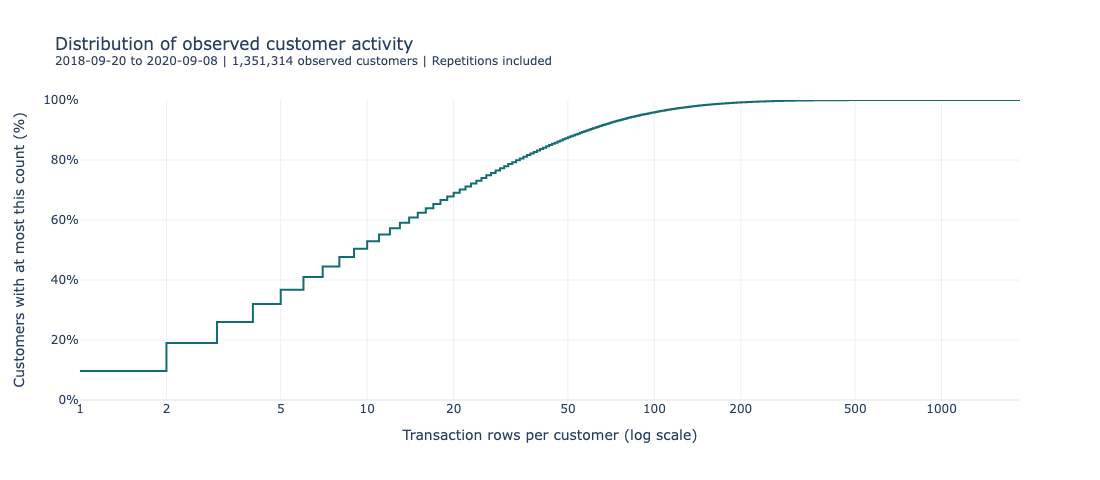

In [35]:
fig = px.line(
    activity_distribution,
    x="transaction_rows",
    y="cumulative_customer_pct",
    line_shape="hv",
    log_x=True,
    color_discrete_sequence=["#146C70"],
    template="plotly_white",
    hover_data={
        "customers": ":,",
        "cumulative_customer_pct": ":.2f",
    },
    labels={
        "transaction_rows": (
            "Transaction rows per customer (log scale)"
        ),
        "cumulative_customer_pct": (
            "Customers with at most this count (%)"
        ),
        "customers": "Customers at this exact count",
    },
    title=(
        "Distribution of observed customer activity"
        f"<br><sup>{EDA_START.date()} to "
        f"{(EDA_END_EXCLUSIVE - pd.Timedelta(days=1)).date()}"
        f" | {observed_customers:,} observed customers"
        " | Repetitions included</sup>"
    ),
)

fig.update_layout(
    width=1100,
    height=480,
    showlegend=False,
)

fig.update_yaxes(
    range=[0, 100],
    ticksuffix="%",
)

activity_ticks = [
    1, 2, 5, 10, 20, 50, 100, 200, 500, 1000
]

fig.update_xaxes(
    tickmode="array",
    tickvals=activity_ticks,
    ticktext=[str(value) for value in activity_ticks],
)

fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)

### 4.4. Interpretation Scope

This analysis describes transaction-row frequency among customers
with observed history in the declared interval.

It does not yet distinguish:
- several rows on one purchase day from purchases across many days;
- repeated purchases from distinct purchased articles;
- recent activity from older activity.

Low observed frequency may also reflect a short observed history.
These distinctions are addressed by the following customer analyses.

### 4.5. Frequency Findings

The analysis includes 1,351,314 observed customers and reconciles
with 31,292,772 retained transaction rows.

Exactly one transaction row is observed for 130,217 customers,
representing approximately 9.636% of the population.

Approximately 50.4% of customers have at most nine transaction rows,
and 90.1% have at most 59 rows.

These results describe heterogeneous observed transaction volumes.
They do not yet distinguish recent activity, repeated purchase days
or distinct purchased articles.

### 4.6. Observed Purchase Dates

Compute the first and last observed purchase dates for each customer
within the declared EDA interval.

Within each chunk, aggregate minimum and maximum dates by customer.
Combine these bounds across chunks using the earliest minimum and
the latest maximum.

First observed purchase dates do not establish customer registration
or lifetime purchase history.

In [36]:
customer_date_bounds = {}
customer_date_rows_scanned = 0

with closing(
    iter_eda_chunks(
        columns=["t_dat", "customer_id"]
    )
) as eda_chunks:
    for chunk_number, chunk in enumerate(
        eda_chunks,
        start=1,
    ):
        dated_chunk = chunk.assign(
            t_dat=pd.to_datetime(
                chunk["t_dat"],
                format="%Y-%m-%d",
                errors="raise",
            )
        )

        chunk_bounds = (
            dated_chunk
            .groupby("customer_id", sort=False)
            .agg(
                first_observed_purchase=("t_dat", "min"),
                last_observed_purchase=("t_dat", "max"),
            )
        )

        for customer_id, first_date, last_date in (
            chunk_bounds.itertuples(name=None)
        ):
            previous_bounds = customer_date_bounds.get(
                customer_id
            )

            if previous_bounds is None:
                customer_date_bounds[customer_id] = (
                    first_date,
                    last_date,
                )
            else:
                customer_date_bounds[customer_id] = (
                    min(previous_bounds[0], first_date),
                    max(previous_bounds[1], last_date),
                )

        customer_date_rows_scanned += len(chunk)

        if chunk_number % 50 == 0:
            print(
                f"{customer_date_rows_scanned:,} "
                "eligible transaction rows processed",
                flush=True,
            )

if customer_date_rows_scanned != eda_transaction_rows:
    raise ValueError(
        "Customer date scan differs from the EDA scope."
    )

print(
    f"Completed: {len(customer_date_bounds):,} "
    "customer date bounds."
)

5,000,000 eligible transaction rows processed
10,000,000 eligible transaction rows processed
15,000,000 eligible transaction rows processed
20,000,000 eligible transaction rows processed
25,000,000 eligible transaction rows processed
30,000,000 eligible transaction rows processed
Completed: 1,351,314 customer date bounds.


In [37]:
customer_date_table = (
    pd.DataFrame.from_dict(
        customer_date_bounds,
        orient="index",
        columns=[
            "first_observed_purchase",
            "last_observed_purchase",
        ],
    )
    .rename_axis("customer_id")
    .reset_index()
)

del customer_date_bounds

customer_date_table["customer_id"] = (
    customer_date_table["customer_id"].astype("string")
)

if len(customer_date_table) != observed_customers:
    raise ValueError(
        "Customer date bounds differ from "
        "the observed customer population."
    )

customer_temporal_activity = customer_activity.merge(
    customer_date_table,
    on="customer_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

if not customer_temporal_activity["_merge"].eq("both").all():
    raise ValueError(
        "Some observed customers have no matching date bounds."
    )

customer_temporal_activity = (
    customer_temporal_activity.drop(columns="_merge")
)

valid_date_bounds = (
    customer_temporal_activity["first_observed_purchase"]
    .ge(EDA_START)
    & customer_temporal_activity["last_observed_purchase"]
    .lt(EDA_END_EXCLUSIVE)
    & customer_temporal_activity["first_observed_purchase"]
    .le(
        customer_temporal_activity[
            "last_observed_purchase"
        ]
    )
)

if not valid_date_bounds.all():
    raise ValueError(
        "Customer purchase-date bounds are inconsistent."
    )

print(
    f"Validated date bounds for "
    f"{len(customer_temporal_activity):,} customers."
)

Validated date bounds for 1,351,314 customers.


### 4.7. Recency and Observed Purchase Span

All durations use the EDA cutoff as the reference date.

- Recency: cutoff minus last observed purchase.
- Days since first observed purchase: cutoff minus first observed purchase.
- Observed purchase span: last minus first observed purchase.

Since transactions precede the cutoff, recency is at least one day.

A zero purchase span means that first and last observed purchases
occur on the same date. It does not imply exactly one transaction row.

In [38]:
customer_temporal_activity["recency_days"] = (
    EDA_END_EXCLUSIVE
    - customer_temporal_activity[
        "last_observed_purchase"
    ]
).dt.days

customer_temporal_activity[
    "days_since_first_observed_purchase"
] = (
    EDA_END_EXCLUSIVE
    - customer_temporal_activity[
        "first_observed_purchase"
    ]
).dt.days

customer_temporal_activity[
    "observed_purchase_span_days"
] = (
    customer_temporal_activity[
        "last_observed_purchase"
    ]
    - customer_temporal_activity[
        "first_observed_purchase"
    ]
).dt.days

In [39]:
temporal_summary = (
    customer_temporal_activity[
        [
            "recency_days",
            "days_since_first_observed_purchase",
            "observed_purchase_span_days",
        ]
    ]
    .agg(["min", "median", "max"])
    .T
)

temporal_summary

,min,median,max
recency_days,1.0,149.0,720.0
days_since_first_observed_purchase,1.0,574.0,720.0
observed_purchase_span_days,0.0,203.0,719.0


### 4.8. Recency Distribution

The cumulative distribution reports the percentage of observed
customers whose last purchase occurred at most x days before
the EDA cutoff.

Each observed customer contributes equally.
The horizontal axis uses calendar days on a linear scale.

Recency describes observed purchase timing. It does not establish
churn or future purchase intent.

In [40]:
recency_distribution = (
    customer_temporal_activity["recency_days"]
    .value_counts()
    .sort_index()
    .rename_axis("recency_days")
    .reset_index(name="customers")
)

recency_distribution["cumulative_customer_pct"] = (
    100
    * recency_distribution["customers"].cumsum()
    / observed_customers
)

if int(
    recency_distribution["customers"].sum()
) != observed_customers:
    raise ValueError(
        "Recency distribution differs from "
        "the observed customer population."
    )

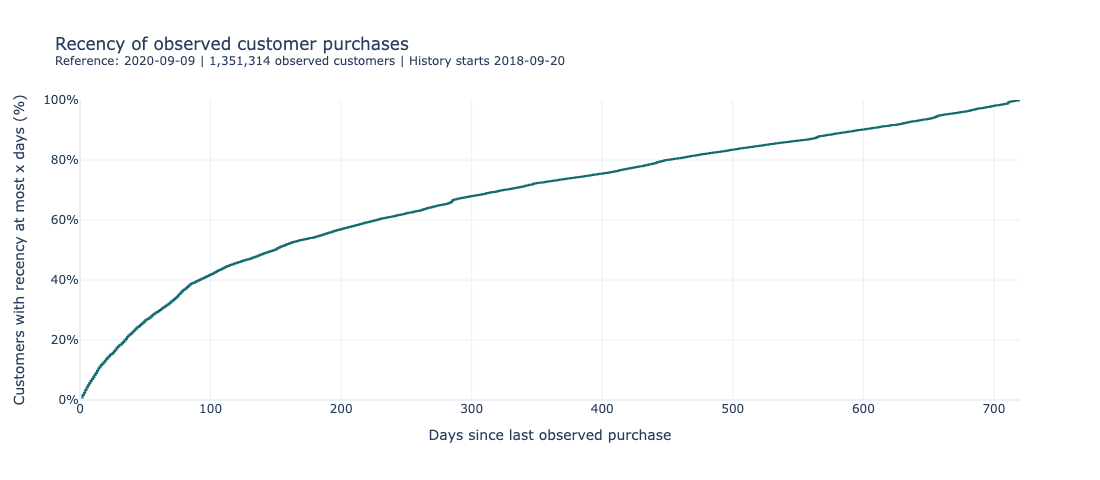

In [41]:
fig = px.line(
    recency_distribution,
    x="recency_days",
    y="cumulative_customer_pct",
    line_shape="hv",
    color_discrete_sequence=["#146C70"],
    template="plotly_white",
    hover_data={
        "customers": ":,",
        "cumulative_customer_pct": ":.2f",
    },
    labels={
        "recency_days": "Days since last observed purchase",
        "cumulative_customer_pct": (
            "Customers with recency at most x days (%)"
        ),
        "customers": "Customers at this exact recency",
    },
    title=(
        "Recency of observed customer purchases"
        f"<br><sup>Reference: {EDA_END_EXCLUSIVE.date()}"
        f" | {observed_customers:,} observed customers"
        f" | History starts {EDA_START.date()}</sup>"
    ),
)

fig.update_layout(
    width=1100,
    height=480,
    showlegend=False,
)

fig.update_xaxes(rangemode="tozero")
fig.update_yaxes(range=[0, 100], ticksuffix="%")

fig.show(
    renderer="plotly_mimetype+png",
    config={"displaylogo": False},
)